In [1]:
import sys
sys.path.append("../src")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from series import load_monthly_revenue

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [6]:
y = load_monthly_revenue()

print("Months:", len(y), "| from", y.index.min().date(), "to", y.index.max().date())
print("Missing values:", int(y.isna().sum()), "| frequency:", y.index.freqstr)
print("Total revenue:", round(y.sum(), 2))
print("Last 12 months:", round(y.tail(12).sum(), 0))
print("First value:", round(y.iloc[0], 0), "| Dec 2019:", round(y["2019-12-01"], 0))
assert len(y) == 61 and y.isna().sum() == 0

Months: 61 | from 2016-01-01 to 2021-01-01
Missing values: 0 | frequency: MS
Total revenue: 55229212.69
Last 12 months: 7738703.0
First value: 649919.0 | Dec 2019: 2477296.0


In [3]:
# If seasonal swings grow with the level of the business, a log transform is justified.
rows = []
for yr in range(2016, 2021):
    sub = y[str(yr)]
    mean_m = sub.mean()
    dec = y[f"{yr}-12-01"]
    rows.append({"year": yr, "avg_month": mean_m, "december": dec,
                 "dec_minus_avg": dec - mean_m, "dec_over_avg": dec / mean_m})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 year    avg_month     december  dec_minus_avg  dec_over_avg
 2016   578,899.46   998,403.46     419,504.00          1.72
 2017   618,451.86 1,287,177.07     668,725.21          2.08
 2018 1,065,746.72 2,082,206.04   1,016,459.32          1.95
 2019 1,522,031.87 2,477,295.85     955,263.98          1.63
 2020   774,552.68   651,526.44    -123,026.24          0.84


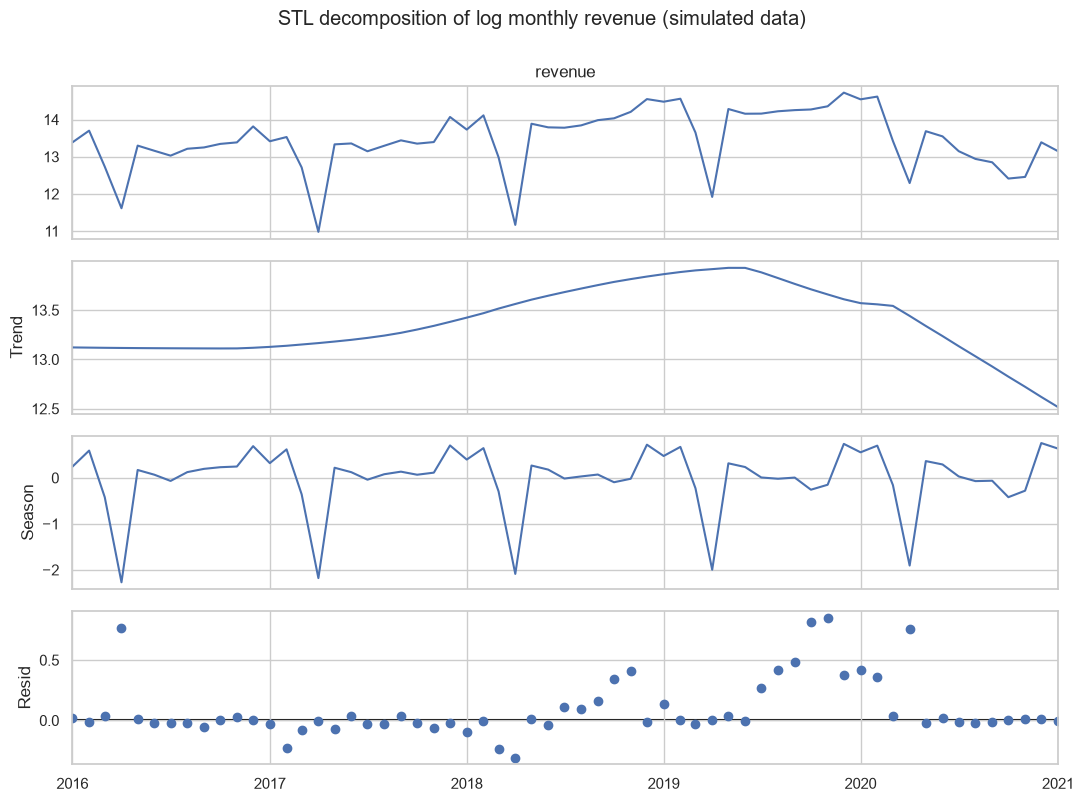

      mean    min    max
Jan 156.00 127.00 189.00
Feb 191.00 181.00 201.00
Mar  75.00  66.00  85.00
Apr  12.00  10.00  15.00
May 131.00 119.00 144.00
Jun 120.00 107.00 134.00
Jul  98.00  94.00 103.00
Aug 103.00  93.00 113.00
Sep 108.00  94.00 122.00
Oct  93.00  66.00 126.00
Nov 100.00  76.00 128.00
Dec 206.00 199.00 213.00

Residual std (log scale): 0.244 | log-series std: 0.797
Residuals beyond 2 std: ['2016-04', '2019-10', '2019-11', '2020-04']
Mean residual by year:
month
2016    0.06
2017   -0.04
2018    0.04
2019    0.28
2020    0.13
2021   -0.00


In [5]:
ly = np.log(y)
stl = STL(ly, period=12, seasonal=13, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(11, 8)
fig.suptitle("STL decomposition of log monthly revenue (simulated data)", y=1.0)
plt.tight_layout()
plt.savefig("../reports/figures/stl_decomposition.png", dpi=150)
plt.show()

# Seasonal factors as percentages of an average month. The column is NOT called "month":
# the series index already has that name, which caused the ambiguity error.
sf = np.exp(stl.seasonal).rename("factor").to_frame()
sf["cal_month"] = sf.index.month
tab = sf.groupby("cal_month")["factor"].agg(["mean", "min", "max"]).mul(100).round(0)
tab.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(tab.to_string())

resid = stl.resid
print("\nResidual std (log scale):", round(resid.std(), 3), "| log-series std:", round(ly.std(), 3))
print("Residuals beyond 2 std:", [d.strftime("%Y-%m") for d in resid.index[abs(resid) > 2 * resid.std()]])
print("Mean residual by year:")
print(resid.groupby(resid.index.year).mean().round(2).to_string())

In [7]:
from backtest import rolling_origin, add_regime, summarise, leakage_check

def seasonal_naive(train, h):
    """Forecast each future month as the same month one year earlier."""
    n = len(train)
    return np.array([train.iloc[n - 12 + k] for k in range(h)])

bt_naive = add_regime(rolling_origin(y, seasonal_naive))

print("Origins:", bt_naive["origin"].nunique(), "| forecasts:", len(bt_naive))
print(bt_naive.groupby("regime")["origin"].nunique().to_string())
print("First origin:", bt_naive["origin"].min().date(), "| last origin:", bt_naive["origin"].max().date())
print("First target:", bt_naive["target"].min().date(), "| last target:", bt_naive["target"].max().date())

ok, n_rows = leakage_check(y, seasonal_naive)
print("Leakage check passed:", ok, "| forecasts compared:", n_rows)

first = bt_naive.iloc[0]
print(f"\nHand check: forecast for {first['target'].date()} = {first['forecast']:,.0f} "
      f"| Jan 2018 actual = {y['2018-01-01']:,.0f} | actual Jan 2019 = {first['actual']:,.0f}")

Origins: 23 | forecasts: 69
regime
pre-break             12
touches 2020 break    11
First origin: 2018-12-01 | last origin: 2020-10-01
First target: 2019-01-01 | last target: 2021-01-01
Leakage check passed: True | forecasts compared: 42

Hand check: forecast for 2019-01-01 = 917,075 | Jan 2018 actual = 917,075 | actual Jan 2019 = 1,940,900


In [8]:
res = summarise(bt_naive)
res.round(1)

n          MAE         RMSE  MAPE_%  \
pre-break          all months    36.00   388,908.80   434,126.00   29.20   
                   excl. Mar/Apr 30.00   417,666.70   456,771.50   24.90   
touches 2020 break all months    33.00   853,960.60 1,010,854.40  215.20   
                   excl. Mar/Apr 27.00 1,017,209.20 1,115,859.60  256.70   
all origins        all months    69.00   611,324.90   766,178.50  118.10   
                   excl. Mar/Apr 57.00   701,660.50   836,430.00  134.70   

                                  WAPE_%  bias_%  
pre-break          all months      25.40  -25.40  
                   excl. Mar/Apr   24.00  -24.00  
touches 2020 break all months     131.80  126.40  
                   excl. Mar/Apr  146.90  142.80  
all origins        all months      55.10   17.00  
                   excl. Mar/Apr   56.40   20.00

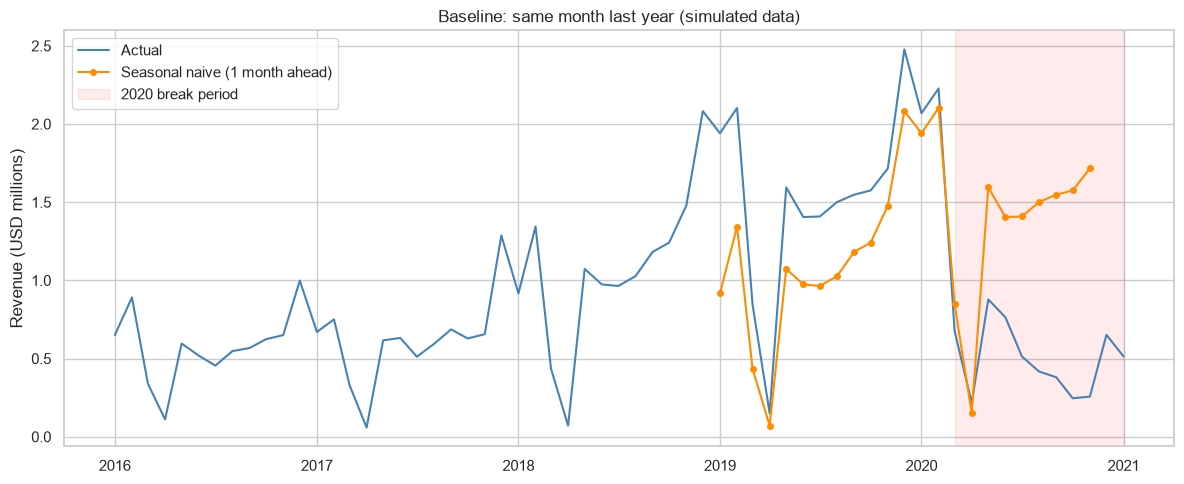

,origin,h,target,actual,forecast,abs_err
65,2020-09-01,3,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
67,2020-10-01,2,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
68,2020-10-01,3,2021-01-01,"513,022.00","2,068,951.00","1,555,930.00"
62,2020-08-01,3,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
64,2020-09-01,2,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
66,2020-10-01,1,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
59,2020-07-01,3,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"
61,2020-08-01,2,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"


In [9]:
h1 = bt_naive[bt_naive["h"] == 1].set_index("target")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="steelblue", label="Actual")
ax.plot(h1.index, h1["forecast"] / 1e6, color="darkorange", marker="o", markersize=4,
        label="Seasonal naive (1 month ahead)")
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08, label="2020 break period")
ax.set_title("Baseline: same month last year (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/baseline_forecast.png", dpi=150)
plt.show()

bt_naive["abs_err"] = (bt_naive["forecast"] - bt_naive["actual"]).abs()
bt_naive.nlargest(8, "abs_err")[["origin", "h", "target", "actual", "forecast", "abs_err"]] \
        .round({"actual": 0, "forecast": 0, "abs_err": 0})

In [10]:
import forecasters as fcs
from backtest import rolling_origin, add_regime, summarise, leakage_check, metrics

ok, n_rows = leakage_check(y, fcs.ets_log)
print("ETS leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()                                   # the leakage check also logged calls; start clean
bt_ets = add_regime(rolling_origin(y, fcs.ets_log))
ets_log = pd.DataFrame(fcs.LOG)

assert len(bt_ets) == 69 and np.isfinite(bt_ets["forecast"]).all() and (bt_ets["forecast"] > 0).all()
print("Origins:", bt_ets["origin"].nunique(), "| forecasts:", len(bt_ets))
print(ets_log["status"].value_counts().to_string())
print("Origins with any warning:", int((ets_log["n_warnings"] > 0).sum()))
print("Damping factor phi: min", ets_log["phi"].min(), "| median", ets_log["phi"].median(), "| max", ets_log["phi"].max())
summarise(bt_ets).round(1)

ETS leakage check passed: True | forecasts compared: 42
Origins: 23 | forecasts: 69
status
ok    23
Origins with any warning: 0
Damping factor phi: min 0.919 | median 0.956 | max 0.995


n        MAE       RMSE  MAPE_%  WAPE_%  \
pre-break          all months    36.00 157,999.30 194,006.60   12.00   10.30   
                   excl. Mar/Apr 30.00 178,713.20 210,969.90   10.30   10.30   
touches 2020 break all months    33.00 325,628.50 417,170.40   58.70   50.30   
                   excl. Mar/Apr 27.00 369,602.70 455,614.20   65.90   53.40   
all origins        all months    69.00 238,169.80 320,733.20   34.30   21.50   
                   excl. Mar/Apr 57.00 269,134.60 348,933.90   36.70   21.60   

                                  bias_%  
pre-break          all months       8.10  
                   excl. Mar/Apr    8.00  
touches 2020 break all months      36.60  
                   excl. Mar/Apr   39.20  
all origins        all months      16.10  
                   excl. Mar/Apr   16.20

In [11]:
ok, n_rows = leakage_check(y, fcs.sarima_log)
print("SARIMA leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()
bt_sar = add_regime(rolling_origin(y, fcs.sarima_log))
sar_log = pd.DataFrame(fcs.LOG)

assert len(bt_sar) == 69 and np.isfinite(bt_sar["forecast"]).all() and (bt_sar["forecast"] > 0).all()
print(sar_log["status"].value_counts().to_string())
print("Converged fits per origin (of 12): min", sar_log["n_converged"].min(),
      "| median", sar_log["n_converged"].median())
print("\nOrder chosen, by how often:")
print(sar_log["order"].value_counts().to_string())
summarise(bt_sar).round(1)

SARIMA leakage check passed: True | forecasts compared: 42
status
ok    23
Converged fits per origin (of 12): min 8 | median 11.0

Order chosen, by how often:
order
(1, 1, 0)x(1, 1, 0, 12)    9
(0, 1, 1)x(1, 1, 0, 12)    8
(0, 1, 1)x(0, 1, 1, 12)    4
(1, 1, 1)x(1, 1, 0, 12)    2


n        MAE       RMSE  MAPE_%  WAPE_%  \
pre-break          all months    36.00 303,693.30 355,373.70   19.30   19.80   
                   excl. Mar/Apr 30.00 358,739.30 389,058.80   20.80   20.60   
touches 2020 break all months    33.00 373,096.20 484,065.30   71.30   57.60   
                   excl. Mar/Apr 27.00 416,926.30 525,817.70   79.10   60.20   
all origins        all months    69.00 336,886.00 421,848.80   44.20   30.40   
                   excl. Mar/Apr 57.00 386,301.60 458,947.60   48.40   31.10   

                                  bias_%  
pre-break          all months      18.50  
                   excl. Mar/Apr   19.90  
touches 2020 break all months      51.90  
                   excl. Mar/Apr   55.70  
all origins        all months      27.90  
                   excl. Mar/Apr   29.30

In [12]:
models = {"Seasonal naive": bt_naive, "ETS": bt_ets, "SARIMA": bt_sar}

rows = []
for name, b in models.items():
    for reg in ["pre-break", "touches 2020 break"]:
        m = metrics(b[b["regime"] == reg])
        rows.append({"model": name, "regime": reg, "WAPE_%": m["WAPE_%"], "bias_%": m["bias_%"], "MAE": m["MAE"]})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nWAPE % by horizon (months ahead):")
rows = []
for name, b in models.items():
    for reg in ["pre-break", "touches 2020 break"]:
        g = b[b["regime"] == reg]
        rows.append({"model": name, "regime": reg,
                     **{f"h={k}": metrics(g[g["h"] == k])["WAPE_%"] for k in (1, 2, 3)}})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nOrigins where the model's total absolute error beats seasonal naive:")
err = {n: b.assign(ae=(b["forecast"] - b["actual"]).abs()).groupby(["origin", "regime"])["ae"].sum()
       for n, b in models.items()}
for n in ("ETS", "SARIMA"):
    win = (err[n] < err["Seasonal naive"]).groupby("regime").agg(["sum", "count"])
    print(n, win.rename(columns={"sum": "wins", "count": "origins"}).to_dict("index"))

         model             regime  WAPE_%  bias_%        MAE
Seasonal naive          pre-break   25.40  -25.40 388,908.80
Seasonal naive touches 2020 break  131.80  126.40 853,960.60
           ETS          pre-break   10.30    8.10 157,999.30
           ETS touches 2020 break   50.30   36.60 325,628.50
        SARIMA          pre-break   19.80   18.50 303,693.30
        SARIMA touches 2020 break   57.60   51.90 373,096.20

WAPE % by horizon (months ahead):
         model             regime   h=1    h=2    h=3
Seasonal naive          pre-break 30.00  24.90  21.30
Seasonal naive touches 2020 break 90.10 131.20 198.00
           ETS          pre-break  9.30   9.30  12.20
           ETS touches 2020 break 29.80  47.80  85.50
        SARIMA          pre-break 16.30  20.30  22.80
        SARIMA touches 2020 break 38.30  50.30  97.30

Origins where the model's total absolute error beats seasonal naive:
ETS {'pre-break': {'wins': 12, 'origins': 12}, 'touches 2020 break': {'wins': 7, 'origins'

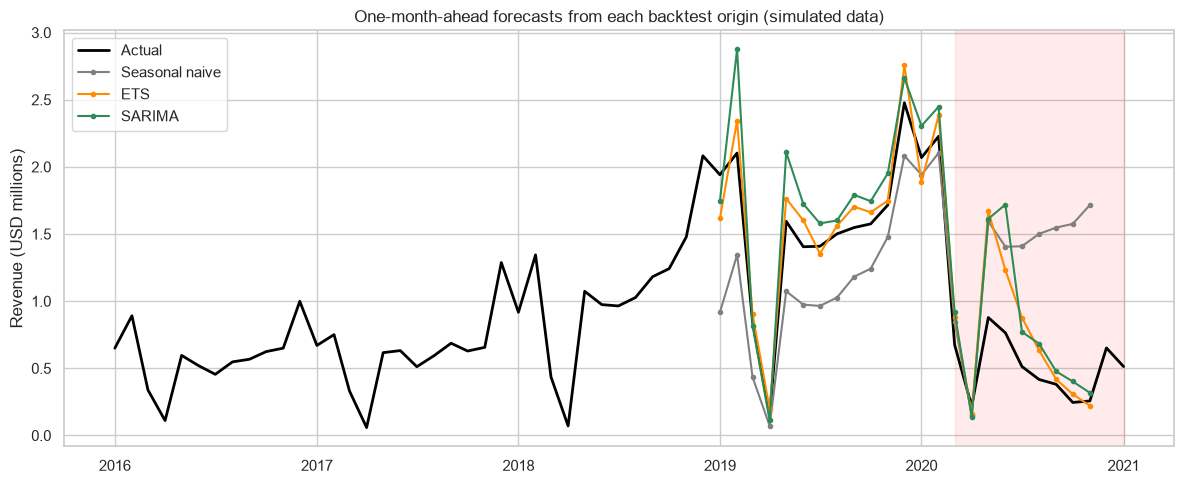

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="black", linewidth=2, label="Actual")
colours = {"Seasonal naive": "grey", "ETS": "darkorange", "SARIMA": "seagreen"}
for name, b in models.items():
    h1 = b[b["h"] == 1].set_index("target")
    ax.plot(h1.index, h1["forecast"] / 1e6, marker="o", markersize=3, color=colours[name], label=name)
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08)
ax.set_title("One-month-ahead forecasts from each backtest origin (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png", dpi=150)
plt.show()